In [1]:
# %%
import pandas as pd
import numpy as np
import psycopg2
import os

# Graficos
import matplotlib.pyplot as plt
import seaborn as sns

# Divisão de dados e validação cruzada
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
 
# Pré-processamento
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
# Balanceamento de classes
from imblearn.over_sampling import SMOTE
 
# Modelo
from xgboost import XGBClassifier, plot_importance


from decimal import Decimal
from dotenv import load_dotenv  

#pd.set_option('display.max_columns', None)
#pd.set_option('display.expand_frame_repr', False)

In [2]:
load_dotenv(dotenv_path=r"E://Projetos//VS_Code//.env")
senha=os.getenv('DB_PASS')
usuario=os.getenv('DB_USER')

def connect_to_db_Otto():
    try:
        conn = psycopg2.connect(
            host='localhost',
            database='otto',
            user=usuario,
            password=senha,
            port=5432
        )
        return conn
    except Exception as e:
        print("Erro ao conectar ao banco de dados:", e)
        return None

In [3]:
def Busca_Otto(conn, table_name):
    try:
        cur = conn.cursor()
        query = f"""
                    SELECT * FROM {table_name}
                    
                    """
        cur.execute(query)
        rows = cur.fetchall()
        columns = [desc[0] for desc in cur.description]  # Obter as colunas logo após a execução da consulta
        return rows, columns
    except Exception as e:
        print(f"Erro ao buscar dados da tabela {table_name}:", e)
        return None, None
    finally:
        cur.close()
        conn.close()


In [4]:

linhas, colunas = Busca_Otto(connect_to_db_Otto(), "Financiamento_propostas")
linhas2, colunas2 = Busca_Otto(connect_to_db_Otto(), "propostas")

In [5]:
df = pd.DataFrame(linhas, columns=colunas)
df2 = pd.DataFrame(linhas2, columns=colunas2)

In [6]:
df3 = df2[['Área', 'codempreendimento', 'comissao', 'data', 'desconto_nominal', 'id_proposta',
 'perda_vpl', 'preÇo_tabela', 'proposta', 'quartos', 'status_proposta']].copy()

In [7]:
df_final = df.merge(df3, left_on='proposal_id', right_on='id_proposta', how='inner')
df_final = df_final.drop(columns=['total_proposta','proposal_id'])


In [8]:
# Transformar status_proposta em valores numéricos
def categorizar_status(status):
    status_lower = str(status).lower()
    
    # Aprovada → 1
    if status_lower.startswith('aprovada'):
        return 1
    # Não aprovada → 0
    elif 'não aprovada' in status_lower or 'nao aprovada' in status_lower:
        return 0
    # Em alteração, Em análise, Aguardando → 2
    elif status_lower.startswith('aguardando') or 'em alteração' in status_lower or 'em análise' in status_lower or 'em analise' in status_lower:
        return 2
    else:
        return 3  # default para casos não previstos

df_final['status_proposta'] = df_final['status_proposta'].apply(categorizar_status)

print("\nValores APÓS transformação:")
print(df_final['status_proposta'].value_counts())
print("\n✅ Mapeamento aplicado:")
print("0 = Não aprovada")
print("1 = Aprovada")
print("2 = Em análise/alteração/Aguardando")


Valores APÓS transformação:
status_proposta
0    5300
1    3085
2     169
3      80
Name: count, dtype: int64

✅ Mapeamento aplicado:
0 = Não aprovada
1 = Aprovada
2 = Em análise/alteração/Aguardando


In [9]:
# Função para visualizar dados por status
def visualizar_por_status(status_valor):
    """
    Filtra e exibe dados por status_proposta
    status_valor: 0 (Não aprovada), 1 (Aprovada), 2 (Em análise/aguardando)
    """
    labels = {0: "Não aprovada", 1: "Aprovada", 2: "Em análise/Aguardando"}
    
    df_filtrado = df_final[df_final['status_proposta'] == status_valor]
    
    print(f"\n{'='*60}")
    print(f"STATUS: {labels.get(status_valor, 'Desconhecido')} (valor {status_valor})")
    print(f"Total de registros: {len(df_filtrado)}")
    print(f"{'='*60}\n")
    
    if len(df_filtrado) > 0:
        print(df_filtrado.head(10))
        print(f"\n... mostrando 10 de {len(df_filtrado)} registros")
    else:
        print("⚠️ Nenhum registro encontrado para este status")
    
    return df_filtrado

# Exemplos de uso - descomente a linha que deseja visualizar:

# Visualizar Não aprovadas (0)
# visualizar_por_status(0)

# Visualizar Aprovadas (1)
# visualizar_por_status(1)

# Visualizar Em análise/Aguardando (2)
# visualizar_por_status(2)

# Ou use diretamente:
status_escolhido = 1  # Altere aqui: 0, 1 ou 2
df_visualizado = visualizar_por_status(status_escolhido)


STATUS: Aprovada (valor 1)
Total de registros: 3085

   af              ato dação fgts    financiamento          mensais  \
4   0   21000.00000000     0    0  383000.00000000  183000.00000000   
5   0  220000.00000000     0    0                0                0   
6   0  220000.00000000     0    0                0                0   
7   0  150000.00000000     0    0  456000.00000000  121600.00000000   
11  0   45000.00000000     0    0  375000.00000000                0   
17  0   40000.00000000     0    0  176218.23000000   48063.42000000   
18  0   40000.00000000     0    0  176218.23000000   48063.42000000   
27  0    6643.27000000     0    0  187303.00000000   98322.00000000   
28  0    6643.27000000     0    0  187303.00000000   98322.00000000   
29  0  250000.00000000     0    0                0                0   

   mensais-af opção_de_dação          reforço reforço-anual-af  ...  \
4           0              0   36000.00000000                0  ...   
5           0         

In [10]:
# Listar valores únicos de status_proposta
print("Valores únicos de status_proposta:")
print(df_final['status_proposta'].unique())
print("\nContagem de cada status:")
print(df_final['status_proposta'].value_counts())

Valores únicos de status_proposta:
[0 1 3 2]

Contagem de cada status:
status_proposta
0    5300
1    3085
2     169
3      80
Name: count, dtype: int64


In [11]:
print(df_final['data'].sample(10))


2608    2025-04-30
1532    2024-12-18
6644    2025-12-09
2350    2025-11-14
743     2023-09-08
1630    2024-07-04
5717    2023-11-27
2880    2025-02-25
8157    2025-08-03
7583    2025-04-09
Name: data, dtype: object


In [12]:
colunas_numericas = [ 'af', 'ato', 'dação', 'fgts','financiamento' ,'mensais', 'mensais-af', 'opção_de_dação',
           'reforço', 'reforço-anual-af', 'reforço-semestral-af', 'registro-itbi-af', 'subsídio','percentual_ato', 'percentual_financiamento', 'percentual_reforco',
           'Área', 'codempreendimento', 'comissao', 'desconto_nominal', 'preÇo_tabela', 'status_proposta']


for col in colunas_numericas:
    df_final[col] = pd.to_numeric(df_final[col], errors='coerce')

# Conversão de datas
for c in [ 'data']:
    df_final[c] = pd.to_datetime(df_final[c], errors='coerce')

df_final['ano_venda'] = (df_final['data'].dt.year).astype(int)
df_final['mes_venda'] = (df_final['data'].dt.month).astype(int)
df_final['trimestre_venda'] = (df_final['data'].dt.quarter).astype(int)
df_final['semana_venda'] = (df_final['data'].dt.isocalendar().week).astype(int)



In [13]:
print(df_final.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8634 entries, 0 to 8633
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   af                        8634 non-null   float64       
 1   ato                       8634 non-null   float64       
 2   dação                     8634 non-null   float64       
 3   fgts                      8634 non-null   float64       
 4   financiamento             8634 non-null   float64       
 5   mensais                   8634 non-null   float64       
 6   mensais-af                8634 non-null   float64       
 7   opção_de_dação            8634 non-null   float64       
 8   reforço                   8634 non-null   float64       
 9   reforço-anual-af          8634 non-null   float64       
 10  reforço-semestral-af      8634 non-null   float64       
 11  registro-itbi-af          8634 non-null   float64       
 12  subsídio            

In [14]:
def preencher_preco_por_empreendimento(df, coluna_preco='preÇo_tabela', coluna_grupo='codempreendimento', verbose=True):
    """
    Preenche valores 0 ou NaN na coluna de preço com a média do empreendimento.
    """
    df = df.copy()
    
    # Contar antes
    zeros_antes = (df[coluna_preco] == 0).sum()
    nulos_antes = df[coluna_preco].isna().sum()
    
    if verbose:
        print(f"Antes: {zeros_antes} zeros, {nulos_antes} nulos")
    
    # Substituir 0 por NaN
    df[coluna_preco] = df[coluna_preco].replace(0, np.nan)
    
    # Calcular média por empreendimento
    media_por_empreendimento = df.groupby(coluna_grupo)[coluna_preco].transform('mean')
    
    # Preencher NaN com a média do empreendimento
    df[coluna_preco] = df[coluna_preco].fillna(media_por_empreendimento)
    
    # Contar depois
    zeros_depois = (df[coluna_preco] == 0).sum()
    nulos_depois = df[coluna_preco].isna().sum()
    
    if verbose:
        print(f"Depois: {zeros_depois} zeros, {nulos_depois} nulos")
        
        # Se ainda houver nulos, são empreendimentos sem nenhum preço válido
        if nulos_depois > 0:
            print(f"\n⚠️ {nulos_depois} registros sem preenchimento (empreendimentos sem preço válido)")
    
    df['percentual_proposta'] = df['proposta'] / df['preÇo_tabela']
    return df
 
# Usar
df_final = preencher_preco_por_empreendimento(df_final)

df_final = df_final.dropna()


Antes: 456 zeros, 980 nulos
Depois: 0 zeros, 364 nulos

⚠️ 364 registros sem preenchimento (empreendimentos sem preço válido)


In [15]:
print(df_final.shape)

(8169, 32)


In [16]:
# def encode_categoricals(df, verbose=True):
#     """
#     Converte todas as colunas não numéricas em códigos numéricos (Label Encoding).
#     """
#     df = df.copy()
#         # Drop de colunas  , 'CdContrato', 'DtVenda'
#     cols_drop = [ 
#         'CdContrato', 'DtVenda','pago'
#     ]
#     df.drop(columns=[c for c in cols_drop if c in df.columns], inplace=True, errors='ignore')
#     encoders = {}
#     cat_cols = df.select_dtypes(include=['object', 'string', 'category']).columns

#     for col in cat_cols:
#         le = LabelEncoder()
#         df[col] = le.fit_transform(df[col].astype(str).fillna('NaN'))
#         encoders[col] = le


#     if verbose:
#         print(f"Colunas convertidas ({len(cat_cols)}): {list(cat_cols)}")
#     return df, encoders


# df, encoders = encode_categoricals(df_final, verbose=True)

In [17]:
# def apply_encoders(df, encoders):
#     """
#     Aplica encoders salvos a um novo DataFrame.
#     - Garante que valores não vistos sejam tratados como 'NaN'.
#     - Adiciona 'NaN' às classes do encoder, se ainda não existir.
#     """
#     df = df.copy()

#     for col, le in encoders.items():
#         if col in df.columns and col != 'CdContrato':  # evita codificar o identificador
#             df[col] = df[col].astype(str).fillna('NaN')

#             # Adiciona 'NaN' à lista de classes, se necessário
#             if 'NaN' not in le.classes_:
#                 le.classes_ = np.append(le.classes_, 'NaN')

#             # Substitui categorias novas por 'NaN'
#             df[col] = df[col].apply(lambda x: x if x in le.classes_ else 'NaN')

#             # Faz a transformação segura
#             df[col] = le.transform(df[col])

#     return df
# df_projecao = apply_encoders(df_final, encoders)
# # temD = df_projecao[['tem_D','CdContrato']]


In [18]:
df_final.drop(columns=['data', 'reforço-semestral-af','fgts','registro-itbi-af','subsídio'], errors='ignore',inplace=True)

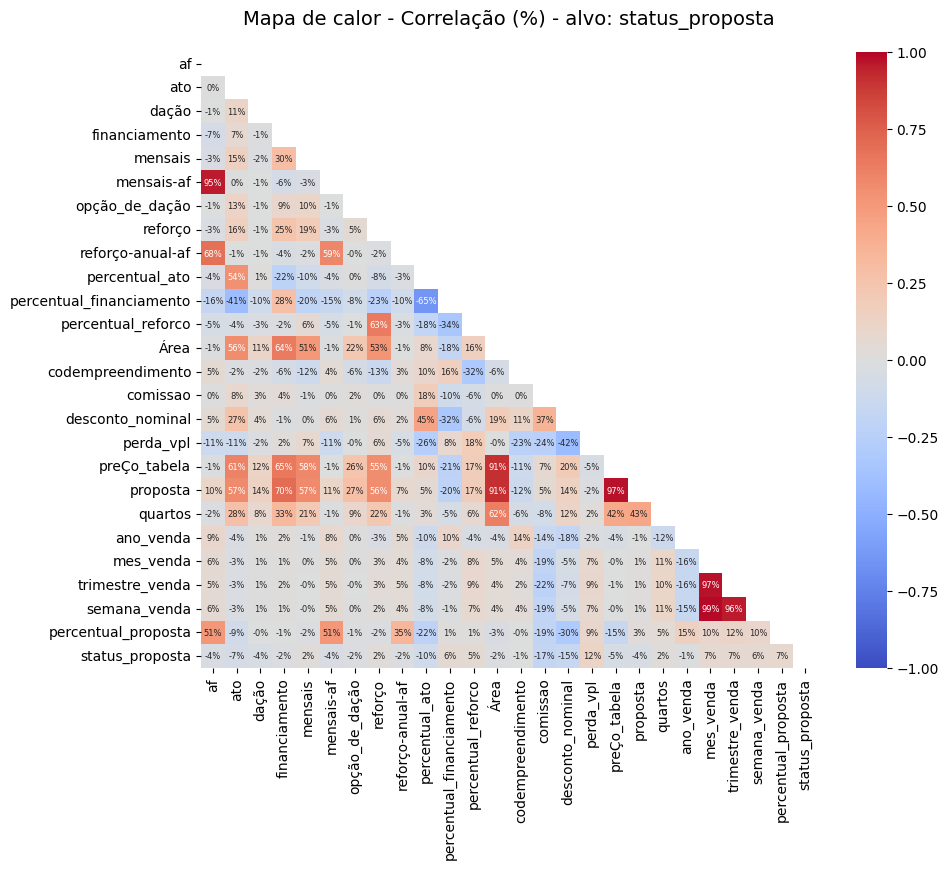

In [19]:
def plot_correlation_heatmap(df: pd.DataFrame, target: str, annot_size: int):
    corr = df.corr(numeric_only=True)

    # move a variável alvo para a última linha e coluna
    cols = [c for c in corr.columns if c != target] + [target]
    corr = corr.loc[cols, cols]

    mask = np.triu(np.ones_like(corr, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".0%",
        cmap="coolwarm",
        vmin=-1, vmax=1,
        cbar=True,
        square=True,
        annot_kws={"size": annot_size}
    )
    plt.title(f"Mapa de calor - Correlação (%) - alvo: {target}", fontsize=14, pad=20)
    plt.show()

# exemplo de uso
plot_correlation_heatmap(df_final, target='status_proposta', annot_size=6)

In [20]:
def percentual_nulos(df, apenas_com_nulos=True):
    total_linhas = len(df)
    nulos = df.isna().sum()
    percentual = (nulos / total_linhas * 100).round(2)
    
    resultado = pd.DataFrame({
        'coluna': nulos.index,
        'nulos': nulos.values,
        'percentual': percentual.values
    })
    
    if apenas_com_nulos:
        resultado = resultado[resultado['nulos'] > 0]
    
    return resultado.sort_values('percentual', ascending=False).reset_index(drop=True)
 
# Mostrar apenas colunas com nulos
print(percentual_nulos(df_final, apenas_com_nulos=True))
 
# Mostrar todas as colunas
print(percentual_nulos(df_final, apenas_com_nulos=False))

Empty DataFrame
Columns: [coluna, nulos, percentual]
Index: []
                      coluna  nulos  percentual
0                         af      0         0.0
1                        ato      0         0.0
2                      dação      0         0.0
3              financiamento      0         0.0
4                    mensais      0         0.0
5                 mensais-af      0         0.0
6             opção_de_dação      0         0.0
7                    reforço      0         0.0
8           reforço-anual-af      0         0.0
9             percentual_ato      0         0.0
10  percentual_financiamento      0         0.0
11        percentual_reforco      0         0.0
12                      Área      0         0.0
13         codempreendimento      0         0.0
14                  comissao      0         0.0
15          desconto_nominal      0         0.0
16               id_proposta      0         0.0
17                 perda_vpl      0         0.0
18              preÇo_tab

In [21]:
# Separar os dados em diferentes dataframes

# 1. Remover todas as linhas com status_proposta = 3
df_final_limpo = df_final[df_final['status_proposta'] != 3].copy()

# 2. df_projecao: apenas linhas com status_proposta = 2 (Em análise/Aguardando)
df_projecao = df_final_limpo[df_final_limpo['status_proposta'] == 2].copy()
df_projecao = df_projecao[df_projecao['ano_venda'] >= 2026]
# 3. df_treino: apenas linhas com status_proposta = 0 ou 1 (Não aprovada e Aprovada)
df_treino = df_final_limpo[df_final_limpo['status_proposta'].isin([0, 1])].copy()

In [22]:
target = 'status_proposta'

# Lista de colunas para remover (adicione aqui as colunas que você quer remover)
colunas_para_remover = [target, 'id_proposta']  # Exemplo: removendo target e id_proposta

# df = df.dropna(axis=1)
X = df_treino.drop(colunas_para_remover, axis=1, errors='ignore')  # errors='ignore' evita erro se coluna não existir
y = df_treino[target]


# Separar variáveis numéricas e categóricas
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
# cat_cols = X.select_dtypes(include=['object']).columns

# ============================================
# 2. Split treino/teste + SMOTE
# ============================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Balanceamento
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# ============================================
# 3. Pré-processamento
# ============================================
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols)
])

# ============================================
# 4. Definição do modelo base
# ============================================
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    use_label_encoder=False,
    random_state=42,
    n_jobs=-1
)

# ============================================
# 5. Grade de hiperparâmetros
# ============================================
param_grid = { 'clf__max_depth': [3, 5, 7, 9],
               'clf__n_estimators': [200,500],
                 'clf__learning_rate': [0.01, 0.03, 0.05, 0.1],
                   'clf__subsample': [0.8], 
                   'clf__colsample_bytree': [0.8],
                     'clf__scale_pos_weight': [2.5, 3] }


# ============================================
# 6. Pipeline completo
# ============================================
pipe = Pipeline([
    ('prep', preprocess),
    ('clf', xgb)
])

# ============================================
# 7. Otimização com GridSearchCV
# ============================================
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=2
)


grid.fit(X_train_res, y_train_res)

print("🔍 Melhor combinação de hiperparâmetros:")
print(grid.best_params_)
print("Melhor AUC (cross-val):", grid.best_score_)

# ============================================
# 8. Avaliação no conjunto de teste
# ============================================
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]



Fitting 3 folds for each of 64 candidates, totalling 192 fits


e:\Projetos\VS_Code\.venv\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:01:16] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


🔍 Melhor combinação de hiperparâmetros:
{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 9, 'clf__n_estimators': 500, 'clf__scale_pos_weight': 3, 'clf__subsample': 0.8}
Melhor AUC (cross-val): 0.8884567066595285


## 🔍 Avaliação de Métricas do Modelo

📊 Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.80      1003
           1       0.67      0.69      0.68       589

    accuracy                           0.76      1592
   macro avg       0.74      0.74      0.74      1592
weighted avg       0.76      0.76      0.76      1592

Acurácia (Accuracy): 0.76
- Mede a proporção total de acertos do modelo.

Precisão (Precision) [classe 1]: 0.67
- Mede quantos dos casos previstos como positivos realmente eram positivos.

Recall (Sensibilidade) [classe 1]: 0.69
- Mede quantos positivos reais o modelo capturou.

F1-Score [classe 1]: 0.68
- Combina precisão e recall em uma única métrica de equilíbrio.

AUC (Área sob a curva ROC): 0.837
- Mede a capacidade de separar positivos de negativos.



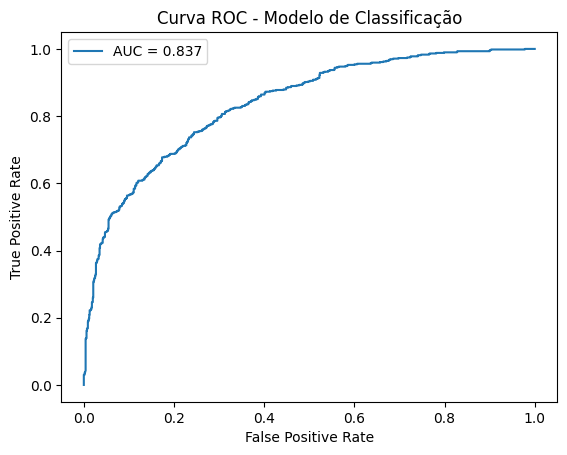

### 📊 Matriz de Confusão:
        Prev_0  Prev_1
Real_0     798     205
Real_1     182     407


<Figure size 1000x700 with 0 Axes>

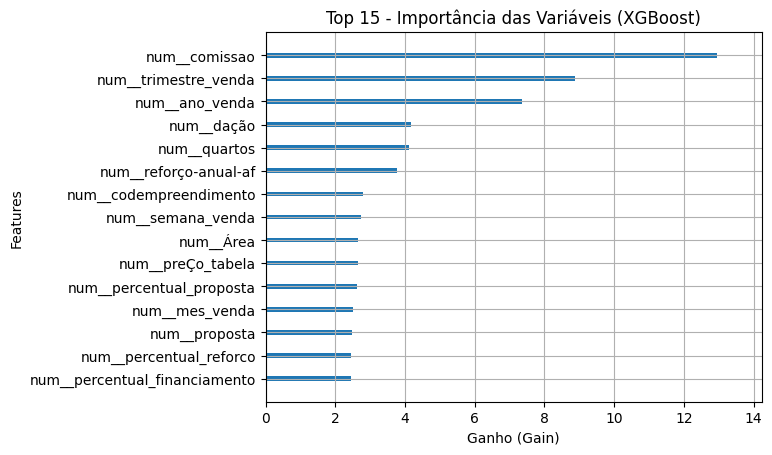

e:\Projetos\VS_Code\.venv\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:01:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


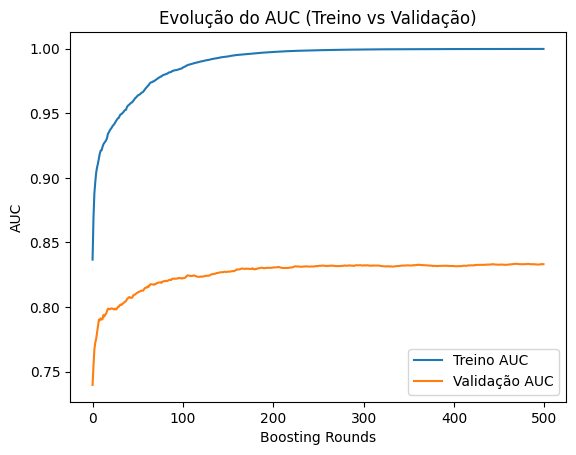


✅ Avaliação concluída.



In [23]:
def exibir_metricas_dinamico(y_true, y_pred, y_prob=None, positive_label=None):
    """
    Exibe as principais métricas de classificação de forma segura e detalhada.
    - Evita KeyError mesmo que o label '1' não exista.
    - Calcula AUC e plota curva ROC se y_prob for informado.
    - Funciona com labels binários, categóricos ou numéricos.

    Parâmetros:
    -----------
    y_true : array-like
        Valores reais da variável alvo.
    y_pred : array-like
        Predições do modelo.
    y_prob : array-like (opcional)
        Probabilidades previstas para a classe positiva.
    positive_label : valor (opcional)
        Define explicitamente qual classe é considerada "positiva".
        Se None, será inferida automaticamente.
    """
    print("## 🔍 Avaliação de Métricas do Modelo\n")
    print("📊 Classification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    # Inferir classe positiva se não especificada
    labels = np.unique(y_true)
    if positive_label is None:
        positive_label = 1 if set(labels) <= {0, 1} else labels[-1]

    # Métricas básicas
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary', pos_label=positive_label, zero_division=0
    )

    print(f"Acurácia (Accuracy): {acc:.2f}")
    print("- Mede a proporção total de acertos do modelo.\n")

    print(f"Precisão (Precision) [classe {positive_label}]: {prec:.2f}")
    print("- Mede quantos dos casos previstos como positivos realmente eram positivos.\n")

    print(f"Recall (Sensibilidade) [classe {positive_label}]: {rec:.2f}")
    print("- Mede quantos positivos reais o modelo capturou.\n")

    print(f"F1-Score [classe {positive_label}]: {f1:.2f}")
    print("- Combina precisão e recall em uma única métrica de equilíbrio.\n")

    # AUC e curva ROC
    if y_prob is not None:
        try:
            auc = roc_auc_score(y_true, y_prob)
            print(f"AUC (Área sob a curva ROC): {auc:.3f}")
            print("- Mede a capacidade de separar positivos de negativos.\n")

            fpr, tpr, _ = roc_curve(y_true, y_prob, pos_label=positive_label)
            plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title('Curva ROC - Modelo de Classificação')
            plt.legend()
            plt.show()
        except ValueError:
            print("⚠️  AUC/ROC não pôde ser calculado (verifique y_prob e classes).")

    # Matriz de confusão
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    print("### 📊 Matriz de Confusão:")
    print(pd.DataFrame(cm, index=[f"Real_{l}" for l in labels],
                             columns=[f"Prev_{l}" for l in labels]))
    # Extrair nomes do ColumnTransformer
    feature_names = best_model.named_steps['prep'].get_feature_names_out(X.columns)

    # Converter para lista pura de strings
    feature_names = feature_names.tolist()

    # Aplicar ao booster
    xgb_model = best_model.named_steps['clf']
    booster = xgb_model.get_booster()
    booster.feature_names = feature_names  # ✅ agora funciona

    # Plotar importância com nomes originais

    plt.figure(figsize=(10, 7))
    plot_importance(
        booster,
        importance_type='gain',
        max_num_features=15,
        xlabel='Ganho (Gain)',
        show_values=False
    )
    plt.title('Top 15 - Importância das Variáveis (XGBoost)')
    plt.show()

    # Extrai o melhor modelo do grid
    best_params = grid.best_params_
    best_xgb = XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        use_label_encoder=False,
        random_state=42,
        **{k.replace('clf__',''): v for k,v in best_params.items()}
    )

    # Reentreina com dados de treino e validação
    eval_set = [(X_train_res, y_train_res), (X_test, y_test)]
    best_xgb.fit(X_train_res, y_train_res, eval_set=eval_set, verbose=False)

    # Agora sim, você pode acessar o histórico
    evals_result = best_xgb.evals_result()

    # Plot AUC treino vs validação
    epochs = len(evals_result['validation_0']['auc'])
    plt.plot(range(epochs), evals_result['validation_0']['auc'], label='Treino AUC')
    plt.plot(range(epochs), evals_result['validation_1']['auc'], label='Validação AUC')
    plt.xlabel('Boosting Rounds')
    plt.ylabel('AUC')
    plt.title('Evolução do AUC (Treino vs Validação)')
    plt.legend()
    plt.show()



    print("\n✅ Avaliação concluída.\n")


# Exemplo de uso:
exibir_metricas_dinamico(y_test, y_pred, y_prob)

In [24]:
from tkinter.filedialog import asksaveasfilename
from tkinter import Tk

# 3. gerar previsões
y_pred_novos = best_model.predict(df_projecao)
y_prob_novos = best_model.predict_proba(df_projecao)[:, 1]

# 4. salvar
df_projecao['Prob_Aprovacao'] = y_prob_novos
df_projecao['Prev_Aprovacao'] = y_pred_novos


In [28]:
# Preparar dados para inserir no PostgreSQL
df_postgres = pd.DataFrame({
    'id_proposta': df_projecao['id_proposta'].astype(str),
    'Prev_Aprovacao': df_projecao['Prev_Aprovacao'].astype(str),
    'Prob_Aprovacao': df_projecao['Prob_Aprovacao'].astype(float)
})

print("📊 Dados preparados para inserção:")
print(f"Total de registros: {len(df_postgres)}")
print("\nAmostra dos dados:")
df_postgres.drop_duplicates(inplace=True)
print(df_postgres)
print(f"\nTipos de dados:")
print(df_postgres.dtypes)

📊 Dados preparados para inserção:
Total de registros: 9

Amostra dos dados:
                               id_proposta Prev_Aprovacao  Prob_Aprovacao
1699  311734a3-eb76-408a-a36d-a9f1190566f0              1        0.780671
2402  467593e5-3274-4cbf-98bc-8e02c771e892              1        0.660602
3750  6ebfbf4b-e471-4268-9ef7-a2d496408a05              1        0.504987
6186  b76c9a49-6e9e-4039-9c86-91434f9927f8              1        0.818992
6376  bd8f2b40-4e80-46b3-8074-39843ff41a33              0        0.286681
6901  cda4aefb-5603-4c4e-b494-d8f2ea5abf9f              0        0.437460

Tipos de dados:
id_proposta        object
Prev_Aprovacao     object
Prob_Aprovacao    float64
dtype: object


In [35]:
# Conectar ao banco e inserir dados
def inserir_dados_postgres(df, tabela='prev_propostas_aprov'):
    """
    Conecta ao banco PostgreSQL, limpa a tabela e insere novos dados
    """
    conn = None
    try:
        # 1. Conectar ao banco
        conn = connect_to_db_Otto()
        if conn is None:
            print("❌ Erro: Não foi possível conectar ao banco de dados")
            return False
        
        cur = conn.cursor()
        print("✅ Conectado ao banco de dados")
        
        # 2. Verificar se a tabela existe e limpar
        cur.execute(f"""
            SELECT EXISTS (
                SELECT FROM information_schema.tables 
                WHERE table_name = '{tabela}'
            );
        """)
        tabela_existe = cur.fetchone()[0]
        
        if tabela_existe:
            cur.execute(f"DELETE FROM {tabela};")
            print(f"🗑️  Tabela '{tabela}' limpa com sucesso")
        else:
            # Criar tabela se não existir
            cur.execute(f"""
                CREATE TABLE {tabela} (
                    id_proposta TEXT,
                    prev_aprovacao TEXT,
                    prob_aprovacao NUMERIC
                );
            """)
            print(f"📋 Tabela '{tabela}' criada com sucesso")
        
        # 3. Inserir dados
        registros_inseridos = 0
        for idx, row in df.iterrows():
            cur.execute(f"""
                INSERT INTO {tabela} (id_proposta, prev_aprovacao, prob_aprovacao)
                VALUES (%s, %s, %s)
            """, (row['id_proposta'], row['Prev_Aprovacao'], row['Prob_Aprovacao']))
            registros_inseridos += 1
        
        # 4. Commit
        conn.commit()
        print(f"✅ {registros_inseridos} registros inseridos com sucesso!")
        
        # 5. Verificar inserção
        cur.execute(f"SELECT COUNT(*) FROM {tabela};")
        total = cur.fetchone()[0]
        print(f"📊 Total de registros na tabela: {total}")
        
        return True
        
    except Exception as e:
        print(f"❌ Erro ao inserir dados: {e}")
        if conn:
            conn.rollback()
        return False
        
    finally:
        if conn:
            cur.close()
            conn.close()
            print("🔌 Conexão fechada")

# Executar inserção
inserir_dados_postgres(df_postgres)

✅ Conectado ao banco de dados
🗑️  Tabela 'prev_propostas_aprov' limpa com sucesso
✅ 6 registros inseridos com sucesso!
📊 Total de registros na tabela: 6
🔌 Conexão fechada


True